In [49]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import numpy as np
import pandas as pd
import cartopy.crs as ccrs
import geopandas as gpd
from shapely.geometry import Polygon, MultiPolygon, Point
from shapely.ops import transform
import cartopy.feature as cfeature
import matplotlib.patheffects as pe
import textwrap
import matplotlib.colors as colors
import xarray as xr

In [50]:
# display all columns
pd.set_option('display.max_columns', None)

# prevent pandas from wrapping columns to the next line
pd.set_option('display.expand_frame_repr', False)

# allow wider tables
pd.set_option('display.width', 2000)

In [51]:
# read in tc_basins file so we can filter to a specific ocean basin
polygons_dict = {}

with open("tc_basins_NAtl.dat", "r") as f:
    for line in f:
        line = line.strip()
        if not line or line.startswith("#"):
            continue

        parts = line.split(",")
        basin_name = parts[0].replace('"', '')
        n_vertices = int(parts[1])

        lon_vals = list(map(float, parts[2:2+n_vertices]))
        lat_vals = list(map(float, parts[2+n_vertices:2+2*n_vertices]))

        coords = list(zip(lon_vals, lat_vals))
        poly = Polygon(coords)

        if basin_name not in polygons_dict:
            polygons_dict[basin_name] = []
        polygons_dict[basin_name].append(poly)

# Convert to GeoDataFrame
basin_records = []

for name, poly_list in polygons_dict.items():
    if len(poly_list) == 1:
        geom = poly_list[0]
    else:
        geom = MultiPolygon(poly_list)

    basin_records.append({
        "basin name": name,
        "geometry": geom
    })

basins = gpd.GeoDataFrame(basin_records, crs="EPSG:4326")

# fix invalid polygons
basins["geometry"] = basins["geometry"].buffer(0)

# remove empy geometries
basins = basins[~basins.geometry.is_empty]

# read in tc_subbasins_NAtl file
sub_polygons_dict = {}

with open("tc_subbasins_NAtl_v5.dat", "r") as f:
    for line in f:
        line = line.strip()
        if not line or line.startswith("#"):
            continue

        parts = line.split(",")
        sub_basin_name = parts[0].replace('"', '')
        n_vertices = int(parts[1])

        lon_vals = list(map(float, parts[2:2+n_vertices]))
        lon_vals = [(lon + 180) % 360 - 180 for lon in lon_vals]
        lat_vals = list(map(float, parts[2+n_vertices:2+2*n_vertices]))

        coords = list(zip(lon_vals, lat_vals))
        poly = Polygon(coords)

        if sub_basin_name not in sub_polygons_dict:
            sub_polygons_dict[sub_basin_name] = []
        sub_polygons_dict[sub_basin_name].append(poly)

# Convert to GeoDataFrame
sub_basin_records = []

for name, poly_list in sub_polygons_dict.items():
    if len(poly_list) == 1:
        geom = poly_list[0]
    else:
        geom = MultiPolygon(poly_list)

    sub_basin_records.append({
        "sub_basin_name": name,
        "geometry": geom
    })

sub_basins = gpd.GeoDataFrame(sub_basin_records, crs="EPSG:4326",geometry="geometry")

# fix invalid polygons
sub_basins["geometry"] = sub_basins["geometry"].buffer(0)

# remove empty geometries
sub_basins = sub_basins[~sub_basins.geometry.is_empty]

# longitude conversion
import shapely.ops
def shift_lon(geom):
    return shapely.ops.transform(
        lambda x, y: (((x + 180) % 360) - 180, y),
        geom
    )

# shift lon
sub_basins["geometry"] = sub_basins["geometry"].apply(shift_lon)
basins["geometry"] = basins["geometry"].apply(shift_lon)


In [52]:
## read in and filter our syclops data
# path to the classified dataset
ClassifiedData = r"datasets/SyCLoPS/SyCLoPS_classified_ERA5_1940_2024_v7.parquet"

# open the parquet format file (PyArrow package required)
df = pd.read_parquet(ClassifiedData)

# TC Nodes: filter to TCs only, tropical flag = 1 so we are only counting before they become extratropical
# tc = df[(df.Tropical_Flag==1) & ((df.Adjusted_Label=='TC') | (df.Adjusted_Label=='TD')) & ~(df['Track_Info'].str.contains('QS', case=False, na=False))]
tc = df[(df.Tropical_Flag==1) & (df.Adjusted_Label=='TC') & ~(df['Track_Info'].str.contains('QS', case=False, na=False))]

# sort by ISOTIME
tc = tc.sort_values(['ISOTIME'])

# origin nodes
tc_origin = (
    tc
    .groupby('TID', as_index=False)
    .head(1)
)

# convert lon to -180-180 from 0-360
tc_origin['LON'] = ((tc_origin['LON'] + 180) % 360) - 180

# Northern Hemisphere only
tc_origin = tc_origin[tc_origin["LAT"] >= 0].copy()

# hurricane season only
tc_origin["month"] = tc_origin["ISOTIME"].dt.month
tc_origin = tc_origin[tc_origin["month"].between(6, 10)].copy()

# create 5deg lat/lon bins for TC data
tc_origin["LON_bin"] = np.floor(tc_origin["LON"] / 5) * 5
tc_origin["LAT_bin"] = np.floor(tc_origin["LAT"] / 5) * 5

# convert LAT and LON to a new column Points which contains (lon, lat) and convert to a geo data frame so we can filter using polygons
tc_points = gpd.GeoDataFrame(
    tc_origin, 
    geometry = gpd.points_from_xy(tc_origin.LON, tc_origin.LAT),
    crs = "EPSG:4326"
)

# filter points to North Atlantic
tc_filtered = gpd.sjoin(
    tc_points,
    basins[basins["basin name"] == "N Atlantic"],
    how = "inner",
    predicate = "within"
)

# filter to columns we need
tc_filtered = tc_filtered[['TID', 'LON', 'LAT', 'ISOTIME','LON_bin', 'LAT_bin']]

# create day column to match on day instead of hour since variable data is daily only
tc_filtered["date"] = pd.to_datetime(tc_filtered["ISOTIME"]).dt.floor("D")

print(tc_filtered)


             TID    LON    LAT             ISOTIME  LON_bin  LAT_bin       date
78477       3923 -95.00  31.75 1940-06-10 18:00:00    -95.0     30.0 1940-06-10
103844      5175 -90.25  28.25 1940-08-06 06:00:00    -95.0     25.0 1940-08-06
105990      5290 -79.00  31.00 1940-08-11 12:00:00    -80.0     30.0 1940-08-11
107995      5385 -26.25  14.50 1940-08-13 12:00:00    -30.0     10.0 1940-08-13
107578      5369 -55.25  16.75 1940-08-16 06:00:00    -60.0     15.0 1940-08-16
...          ...    ...    ...                 ...      ...      ...        ...
15007279  738084 -95.25  23.00 2024-10-06 09:00:00   -100.0     20.0 2024-10-06
15009089  738157 -78.75  27.25 2024-10-08 09:00:00    -80.0     25.0 2024-10-08
15007945  738105 -22.25  14.50 2024-10-11 00:00:00    -25.0     10.0 2024-10-11
15013979  738407 -87.25  16.75 2024-10-19 09:00:00    -90.0     15.0 2024-10-19
15014718  738443 -73.00  21.00 2024-10-20 06:00:00    -75.0     20.0 2024-10-20

[908 rows x 7 columns]


In [53]:
# load variable datasets
ds1 = xr.open_mfdataset(
    "datasets/ERA5_1940/sst_dailyMean_ERA5_1940-2025",
    combine="by_coords",
    chunks={"time": 30}
)
ds2 = xr.open_mfdataset(
    "datasets/RHUM/post_processing/post_landmask/yearly/*.nc",
    combine="by_coords",
    chunks={"time": 30}
)
ds3 = xr.open_mfdataset(
    "datasets/u-wind/post_processing/post_landmask/shear_annual/*.nc",
    combine="by_coords",
    chunks={"time": 30}
)
ds4 = xr.open_dataset("datasets/GPI/GPI_EN_calc/post_landmask/GPI_EN_output_daily_landmasked.nc",)

# rename dimensions
ds1 = ds1.rename({
    "valid_time": "time",
    "latitude": "lat",
    "longitude": "lon"
})

# select variable
sst = ds1["sst"]
rhum = ds2["r"]
shear = ds3["wind_shear"]
gpi = ds4["gpi"]

# # define the same 5deg bins used for TC data
# lat_edges = np.arange(0, 95, 5)
# lon_edges = np.arange(-110, 25, 5)

# # Convert SST longitude from 0-360 to -180-180
# sst = sst.assign_coords(
#     lon=((sst.lon + 180) % 360) - 180
# )

# # convert SST from kelvin to C
# sst = sst - 273.15
# sst.attrs["units"] = "°C"

# # sort coordinates
# sst = sst.sortby(["lat", "lon"])
# rhum = rhum.sortby(["lat", "lon"])
# shear = shear.sortby(["lat", "lon"])
# gpi = gpi.sortby(["lat", "lon"])

# # restrict sst to the TC study region
# sst = sst.sel(
#     lat=slice(0, 90),
#     lon=slice(-110, 25)
# )

# # # # # only process dates that actually occur in TC data
# # # # tc_filtered["date"] = pd.to_datetime(tc_filtered["ISOTIME"]).dt.floor("D")
# # # # tc_filtered = tc_filtered[tc_filtered["date"] >= "1981-09-01"]
# # # # dates_needed = pd.DatetimeIndex(tc_filtered["date"].unique())
# # # # sst = sst.sel(time=dates_needed)
# # # # rhum = rhum.sel(time=dates_needed)
# # # # shear = shear.sel(time=dates_needed)

# # bin into 5deg cells
# sst_binned = sst.groupby_bins(
#     "lat",
#     lat_edges,
#     labels=lat_edges[:-1]
# ).mean()
# sst_binned = sst_binned.groupby_bins(
#     "lon",
#     lon_edges,
#     labels=lon_edges[:-1]
# ).mean()

# # rhum
# rhum_binned = rhum.groupby_bins(
#     "lat",
#     lat_edges,
#     labels=lat_edges[:-1]
# ).mean()
# rhum_binned = rhum_binned.groupby_bins(
#     "lon",
#     lon_edges,
#     labels=lon_edges[:-1]
# ).mean()

# # shear
# shear_binned = shear.groupby_bins(
#     "lat",
#     lat_edges,
#     labels=lat_edges[:-1]
# ).mean()
# shear_binned = shear_binned.groupby_bins(
#     "lon",
#     lon_edges,
#     labels=lon_edges[:-1]
# ).mean()

# # gpi
# gpi_binned = gpi.groupby_bins(
#     "lat",
#     lat_edges,
#     labels=lat_edges[:-1]
# ).mean()
# gpi_binned = gpi_binned.groupby_bins(
#     "lon",
#     lon_edges,
#     labels=lon_edges[:-1]
# ).mean()

# # rename to match TC dataframe
# sst_binned = sst_binned.rename({
#     "lat_bins": "LAT_bin",
#     "lon_bins": "LON_bin"
# })
# rhum_binned = rhum_binned.rename({
#     "lat_bins": "LAT_bin",
#     "lon_bins": "LON_bin"
# })
# shear_binned = shear_binned.rename({
#     "lat_bins": "LAT_bin",
#     "lon_bins": "LON_bin"
# })
# gpi_binned = gpi_binned.rename({
#     "lat_bins": "LAT_bin",
#     "lon_bins": "LON_bin"
# })

# # convert variable dataset to a DataFrame
# sst_df = (
#     sst_binned
#     .to_dataframe(name="sst")
#     .reset_index()
# )
# rhum_df = (
#     rhum_binned
#     .to_dataframe(name="rhum")
#     .reset_index()
# )
# shear_df = (
#     shear_binned
#     .to_dataframe(name="shear")
#     .reset_index()
# )
# gpi_df = (
#     gpi_binned
#     .to_dataframe(name="gpi")
#     .reset_index()
# )

# # make sure variables have day columns
# sst_df["date"] = pd.to_datetime(sst_df["time"]).dt.floor("D")
# rhum_df["date"] = pd.to_datetime(rhum_df["time"]).dt.floor("D")
# shear_df["date"] = pd.to_datetime(shear_df["time"]).dt.floor("D")
# gpi_df["date"] = pd.to_datetime(gpi_df["time"]).dt.floor("D")
# # # # # tc_filtered["date"] = pd.to_datetime(tc_filtered["ISOTIME"]).dt.floor("D")

# # merge sst, rhum, and shear onto TC table
# merged = tc_filtered.merge(
#     sst_df[["date", "LAT_bin", "LON_bin", "sst"]],
#     on=["date", "LAT_bin", "LON_bin"],
#     how="left"
# )
# merged = merged.merge(
#     rhum_df[["date", "LAT_bin", "LON_bin", "rhum"]],
#     on=["date", "LAT_bin", "LON_bin"],
#     how="left"
# )
# merged = merged.merge(
#     shear_df[["date", "LAT_bin", "LON_bin", "shear"]],
#     on=["date", "LAT_bin", "LON_bin"],
#     how="left"
# )
# merged = merged.merge(
#     gpi_df[["date", "LAT_bin", "LON_bin", "gpi"]],
#     on=["date", "LAT_bin", "LON_bin"],
#     how="left"
# )

# # filter date if syclops and ds don't match
# merged = merged[merged["date"] >= "1981-09-01"]

# save merged table to csv
# merged.to_csv("datasets/SyCLoPS/tc_sst+shear+rhum+gpi_merged_table_1940-2025.csv")

# print(merged.head())

Caribbean:
  Environment area: 1.0000
  TC area:          1.0000
Eastern Tropics:
  Environment area: 1.0000
  TC area:          1.0000
Gulf (A):
  Environment area: 1.0000
  TC area:          1.0000
Gulf (B):
  Environment area: 1.0000
  TC area:          1.0000
Central Atlantic:
  Environment area: 1.0000
  TC area:          1.0000
Northeastern Seaboard:
  Environment area: 1.0000
  TC area:          1.0000
Southeastern Seaboard:
  Environment area: 1.0000
  TC area:          1.0000


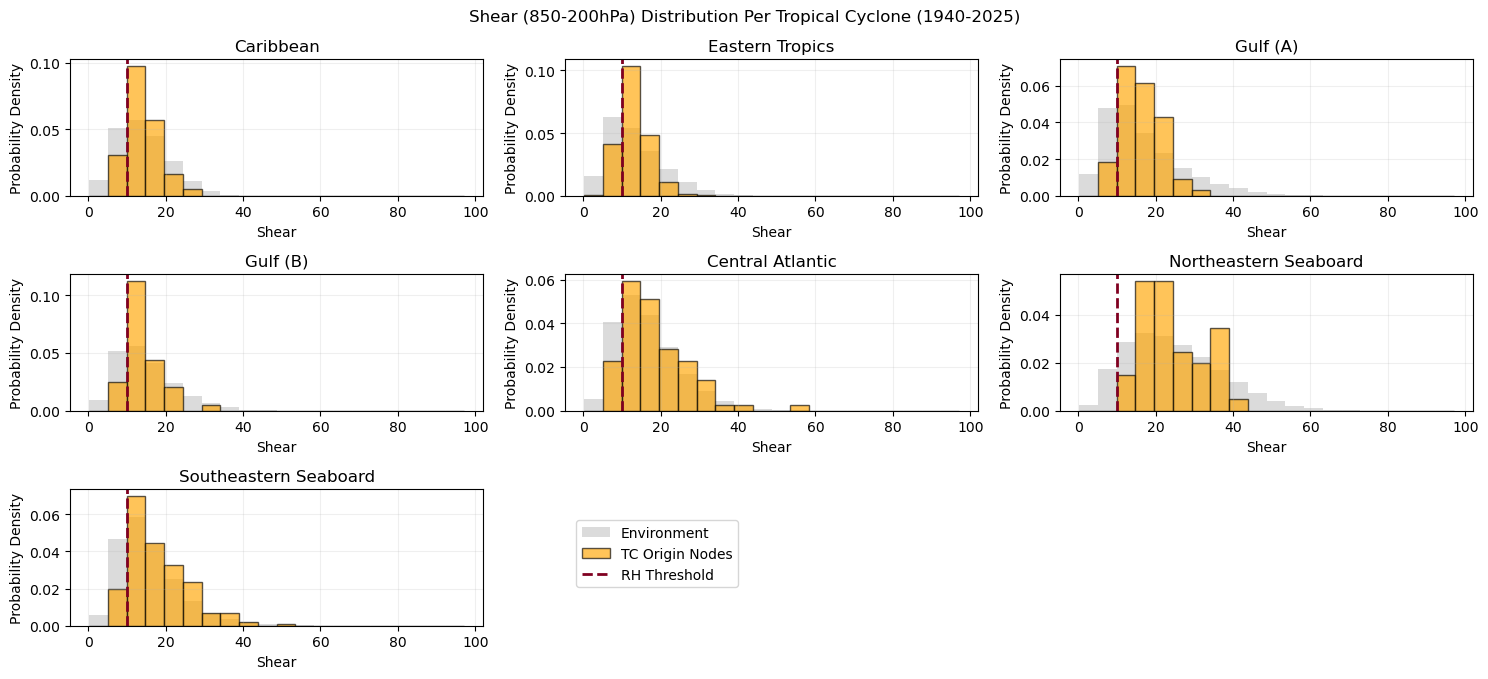

In [47]:
# load merged table
ds = pd.read_csv("datasets/SyCLoPS/tc_sst+shear+rhum+gpi_merged_table_1940-2025.csv")

# convert LAT and LON to a new column Points which contains (lon, lat) and convert to a geo data frame so we can filter using polygons
points = gpd.GeoDataFrame(
    ds, 
    geometry = gpd.points_from_xy(ds.LON, ds.LAT),
    crs = "EPSG:4326"
)

# filter points to North Atlantic
filtered = gpd.sjoin(
    points,
    basins[basins["basin name"] == "N Atlantic"],
    how = "inner",
    predicate = "within"
)

# drop columns we dont need
filtered = filtered[['TID', 'LON', 'LAT', 'ISOTIME', 'sst', 'shear', 'rhum', 'gpi', 'geometry']]

# join sub basins
sb = gpd.sjoin(
    filtered,
    sub_basins[['sub_basin_name', 'geometry']],
    how='left',
    predicate='intersects'
)

# # plot histogram per sub basin
# filter out sub basins with low TCs
keep_subbasins = [
    "Caribbean",
    "Eastern Tropics",
    "Gulf (A)",
    "Gulf (B)",
    "Central Atlantic",
    "Northeastern Seaboard",
    "Southeastern Seaboard"
]

sb_filtered = sb[
    sb["sub_basin_name"].isin(keep_subbasins)
]

# select variable we want to plot (SST, RH, shear)
var = 'shear'

# dictionary containing the environmental datasets
var_dfs = {
    "sst": sst_df,
    "rhum": rhum_df,
    "shear": shear_df,
    "gpi": gpi_df
}

# select the environmental dataset
var_env = var_dfs[var].copy()

# convert 5deg bins to be central points instead of lower corner
var_env["lat_center"] = var_env["LAT_bin"] + 2.5
var_env["lon_center"] = var_env["LON_bin"] + 2.5

# get points
var_env = gpd.GeoDataFrame(
    var_env,
    geometry=gpd.points_from_xy(
        var_env["lon_center"],
        var_env["lat_center"]
    ),
    crs="EPSG:4326"
)

# assign each environmental grid point to a subbasin
var_env = gpd.sjoin(
    var_env,
    sub_basins[["sub_basin_name", "geometry"]],
    how="inner",
    predicate="within"
)

# keep only the same subbasins as the TC data
var_env_filtered = var_env[
    var_env["sub_basin_name"].isin(keep_subbasins)
]

# get the unique sub-basins
subbasins = [
    sb for sb in keep_subbasins
    if sb in sb_filtered["sub_basin_name"].unique()
]

# combine TC and environmental data for the selected variable so we can calculate the range
all_data = pd.concat([
    pd.to_numeric(sb_filtered[var], errors="coerce"),
    pd.to_numeric(var_env_filtered[var], errors="coerce")
]).dropna()

# calculate shared bin edges across all sub-basins
bin_edges = np.histogram_bin_edges(all_data, bins=20)

# create a grid of subplots
n = len(subbasins)
ncols = 3
nrows = int(np.ceil(n / ncols))

fig, axes = plt.subplots(
    nrows=nrows,
    ncols=ncols,
    figsize=(15, 2.5 * nrows),
    sharex=False,
    sharey=False
)

# make axes easy to loop over
axes = np.atleast_1d(axes).flatten()

# plot per sub basin
for ax, subbasin in zip(axes, subbasins):

    # tc data
    tc_data = sb_filtered.loc[
        sb_filtered["sub_basin_name"] == subbasin,
        var
    ].dropna()

    # environmental data for comparison
    env_data = var_env_filtered.loc[
        var_env_filtered["sub_basin_name"] == subbasin,
        var
    ].dropna()

    # env distribution
    ax.hist(
        env_data,
        bins=bin_edges,
        density=True,
        color="lightgray",
        edgecolor="none",
        alpha=0.8,
        label="Environment"
    )

    # tc distribution
    ax.hist(
        tc_data,
        bins=bin_edges,
        density=True,
        color="orange",
        edgecolor="black",
        alpha=0.65,
        label="TC Origin Nodes"
    )

    # threshold
    ax.axvline(
        10,
        color="#800020",
        linestyle="--",
        linewidth=2,
        label="RH Threshold"
    )

    # labels
    ax.set_title(subbasin)
    ax.set_xlabel("Shear")
    ax.tick_params(axis="x", labelbottom=True)
    ax.set_ylabel("Probability Density")
    ax.grid(alpha=0.2)

    # ax.legend()

    # # CHECK: prob densities add up to 1
    # calculate histogram densities
    env_density, _ = np.histogram(
        env_data,
        bins=bin_edges,
        density=True
    )

    tc_density, _ = np.histogram(
        tc_data,
        bins=bin_edges,
        density=True
    )

    # calculate area under each histogram
    env_area = np.sum(env_density * np.diff(bin_edges))
    tc_area = np.sum(tc_density * np.diff(bin_edges))

    print(f"{subbasin}:")
    print(f"  Environment area: {env_area:.4f}")
    print(f"  TC area:          {tc_area:.4f}")

# hide unused axis
for ax in axes[len(subbasins):]:
    ax.set_visible(False)

# add title
plt.suptitle("Shear (850-200hPa) Distribution Per Tropical Cyclone (1940-2025)")

# create one shared legend for the entire figure
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc="lower right",
    bbox_to_anchor=(0.50, 0.20),
    ncol=1,
    frameon=True
)

# leave room for the legend at the bottom
plt.tight_layout(rect=[0, 0.08, 1, 1])

# plt.savefig("images/data_viz/thresholds/TC_only/tcOrigins_rhumTH_histogram_wEnvDist_syclops_noaa_match_perSb.png")
plt.show()


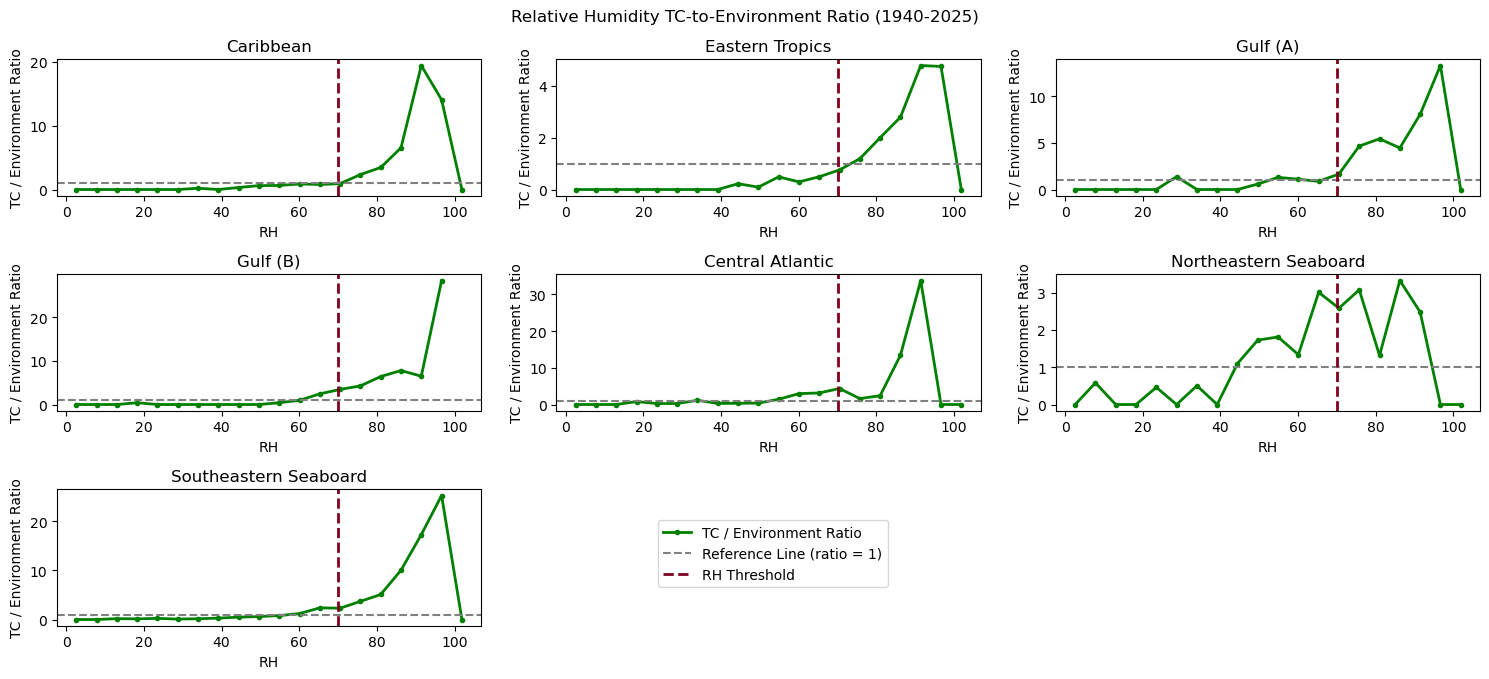

In [46]:
# find ratio of TC dist to env dist
# create figure for the TC to ENV ratio
fig_ratio, axes_ratio = plt.subplots(
    nrows=nrows,
    ncols=ncols,
    figsize=(15, 2.5 * nrows),
    sharex=True,
    sharey=False
)
axes_ratio = np.atleast_1d(axes_ratio).flatten()

# plot the ratio for each sub-basin
for ax, subbasin in zip(axes_ratio, subbasins):

    # get TC data
    tc_data = sb_filtered.loc[
        sb_filtered["sub_basin_name"] == subbasin, var
    ].dropna()

    # get environmental data
    env_data = var_env_filtered.loc[
        var_env_filtered["sub_basin_name"] == subbasin, var
    ].dropna()

    # count observations using the shared bin edges
    tc_counts, _ = np.histogram(tc_data, bins=bin_edges)
    env_counts, _ = np.histogram(env_data, bins=bin_edges)

    # normalize counts to proportions
    tc_fraction = tc_counts / tc_counts.sum()
    env_fraction = env_counts / env_counts.sum()

    # calculate TC-to-environment ratio
    ratio = np.divide(
        tc_fraction,
        env_fraction,
        out=np.full(len(tc_fraction), np.nan),
        where=env_fraction > 0
    )

    # calculate bin centers
    bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

    # plot ratio
    ax.plot(
        bin_centers,
        ratio,
        color="green",
        linewidth=2,
        marker="o",
        markersize=3,
        label="TC / Environment Ratio"
    )

    # reference line: ratio = 1
    ax.axhline(
        1,
        color="gray",
        linestyle="--",
        linewidth=1.5,
        label = "Reference Line (ratio = 1)"
    )

    # threshold
    ax.axvline(
        70,
        color="#800020",
        linestyle="--",
        linewidth=2,
        label="RH Threshold"
    )

    ax.set_title(subbasin)
    ax.set_xlabel("RH")
    ax.tick_params(axis="x", labelbottom=True)
    ax.set_ylabel("TC / Environment Ratio")
    # ax.grid(alpha=0.2)

# hide unused subplots
for ax in axes_ratio[len(subbasins):]:
    ax.set_visible(False)

# add a chart title
plt.suptitle(f"Relative Humidity TC-to-Environment Ratio (1940-2025)")

# Create one shared legend for the entire figure
handles, labels = axes_ratio[0].get_legend_handles_labels()

fig_ratio.legend(
    handles,
    labels,
    loc="lower right",
    bbox_to_anchor=(0.60, 0.20),
    frameon=True
)

plt.tight_layout(rect=[0, 0.08, 1, 1])

plt.savefig("images/data_viz/thresholds/TC_only/tcOrigins_rhumTH_ratio_wEnvDist_syclops_noaa_match_perSb.png")
plt.show()

In [54]:
# check what TC origins were doing before they became the TC origin

# load merged table
og = pd.read_csv("datasets/SyCLoPS/tc_sst+shear+rhum+gpi_merged_table_1940-2025.csv", index_col = 0)

# print(og)

# load original syclops dataset
ClassifiedData = r"datasets/SyCLoPS/SyCLoPS_classified_ERA5_1940_2024_v7.parquet"
df = pd.read_parquet(ClassifiedData)

# get unique TIDs for TC origin nodes
og_TIDs = og["TID"].unique()

# filter the original syclops data to matching TIDs
df_TIDs = df[df["TID"].isin(og_TIDs)].copy()

# convert timestamp column to datetime
df_TIDs["ISOTIME"] = pd.to_datetime(df_TIDs["ISOTIME"])

# find the first timestamp for each TID
pre_og_node = (
    df_TIDs
    .sort_values("ISOTIME")
    .groupby("TID")
    .first()
    .reset_index()
)

# rename columns
pre_og_node = pre_og_node[
    ["TID", "ISOTIME", "Adjusted_Label", "LAT", "LON"]
].rename(columns={
    "ISOTIME": "ISOTIME_ini",
    "Adjusted_Label": "Adjusted_Label_ini",
    "LAT": "LAT_ini",
    "LON": "LON_ini"
})
og = og[
    ["TID", "date", "LAT_bin", "LON_bin", "sst", "rhum", "shear", "gpi"]
].rename(columns={
    "date": "ISOTIME_TC",
    "LAT_bin": "LAT_TC",
    "LON_bin": "LON_TC",
    "sst": "sst_TC",
    "rhum": "rhum_TC",
    "shear": "shear_TC",
    "gpi": "gpi_TC"
})

# convert ISOTIME_ini to just day month year (without timestamp)
pre_og_node["ISOTIME_ini"] = pd.to_datetime(pre_og_node["ISOTIME_ini"]).dt.normalize()

# merge initial TID information with TC origin information
og_merged = og.merge(
    pre_og_node,
    on="TID",
    how="left"
)

# print(og_merged.head())

# now link sub basins to plot
# convert LAT and LON to a new column Points which contains (lon, lat) and convert to a geo data frame so we can filter using polygons
points = gpd.GeoDataFrame(
    og_merged, 
    geometry = gpd.points_from_xy(og_merged.LON_TC, og_merged.LAT_TC),
    crs = "EPSG:4326"
)

# join sub basins
sb = gpd.sjoin(
    points,
    sub_basins[['sub_basin_name', 'geometry']],
    how='left',
    predicate='intersects'
)

# rename sub basin column
sb = sb.rename(columns={"sub_basin_name": "subbasin_TC"})

# drop columns/NAN subbasins we don't need
sb = sb[["TID", "ISOTIME_TC", "LAT_TC", "LON_TC", "sst_TC", "rhum_TC", "shear_TC", "gpi_TC", "ISOTIME_ini", "Adjusted_Label_ini", "LAT_ini", "LON_ini", "subbasin_TC"]]
sb = sb.dropna(subset=["subbasin_TC"])

# print(sb)

# convert LON_ini
sb["LON_ini"] = ((sb["LON_ini"] + 180) % 360) - 180

# now find initiation sub basin
points_2 = gpd.GeoDataFrame(
    sb, 
    geometry = gpd.points_from_xy(sb.LON_ini, sb.LAT_ini),
    crs = "EPSG:4326"
)
sb_2 = gpd.sjoin(
    points_2,
    sub_basins[['sub_basin_name', 'geometry']],
    how='left',
    predicate='intersects'
)
sb_2 = sb_2.rename(columns={"sub_basin_name": "subbasin_ini"})
sb_2 = sb_2[["TID", "ISOTIME_TC", "LAT_TC", "LON_TC", "sst_TC", "rhum_TC", "shear_TC", "gpi_TC", "ISOTIME_ini", "Adjusted_Label_ini", "LAT_ini", "LON_ini", "subbasin_TC", "subbasin_ini"]]

print(sb_2)


        TID  ISOTIME_TC  LAT_TC  LON_TC     sst_TC    rhum_TC   shear_TC     gpi_TC ISOTIME_ini Adjusted_Label_ini  LAT_ini  LON_ini            subbasin_TC           subbasin_ini
0      3923  1940-06-10    30.0   -95.0  27.475739  57.510390  14.353790        NaN  1940-06-10            TLO(ML)    31.00   -95.50               Gulf (B)               Gulf (B)
1      5175  1940-08-06    25.0   -95.0  29.845184  59.350555  10.557420        NaN  1940-08-01                TLO    34.25   -79.50               Gulf (B)  Southeastern Seaboard
2      5290  1940-08-11    30.0   -80.0  28.968277  81.707470  16.878983        NaN  1940-08-06                DST    19.00   -72.00  Southeastern Seaboard              Caribbean
3      5385  1940-08-13    10.0   -30.0  28.394709  94.802570  15.279506        NaN  1940-08-11                TLO    13.75   -17.75        Eastern Tropics        Eastern Tropics
4      5369  1940-08-16    15.0   -60.0  28.070887  74.922874  23.185848        NaN  1940-08-10          

In [70]:
# now pivot to get initial form and location
piv = sb_2.groupby(['subbasin_TC', 'TID', 'Adjusted_Label_ini', 'subbasin_ini'])[
    ['sst_TC', 'rhum_TC', 'shear_TC', 'gpi_TC']
].mean().dropna().reset_index()

print(piv)

               subbasin_TC     TID Adjusted_Label_ini           subbasin_ini     sst_TC    rhum_TC   shear_TC      gpi_TC
0                Caribbean  366912                TLO        Eastern Tropics  28.287678  60.828266  12.755828   52.818284
1                Caribbean  375538                TLO              Caribbean  28.965680  56.628204  16.812553  108.126798
2                Caribbean  392701                DST              Caribbean  28.401493  47.570300   5.812834    9.317271
3                Caribbean  393019                TLO  Southeastern Seaboard  27.887380  55.572163  22.251703   10.466745
4                Caribbean  400603                TLO              Caribbean  28.954250  85.070860  11.977185   41.594066
..                     ...     ...                ...                    ...        ...        ...        ...         ...
127  Southeastern Seaboard  721362                TLO  Southeastern Seaboard  24.686758  65.953660  34.652687    0.482598
128  Southeastern Seaboa

TypeError: Axes.table() got multiple values for argument 'ax'

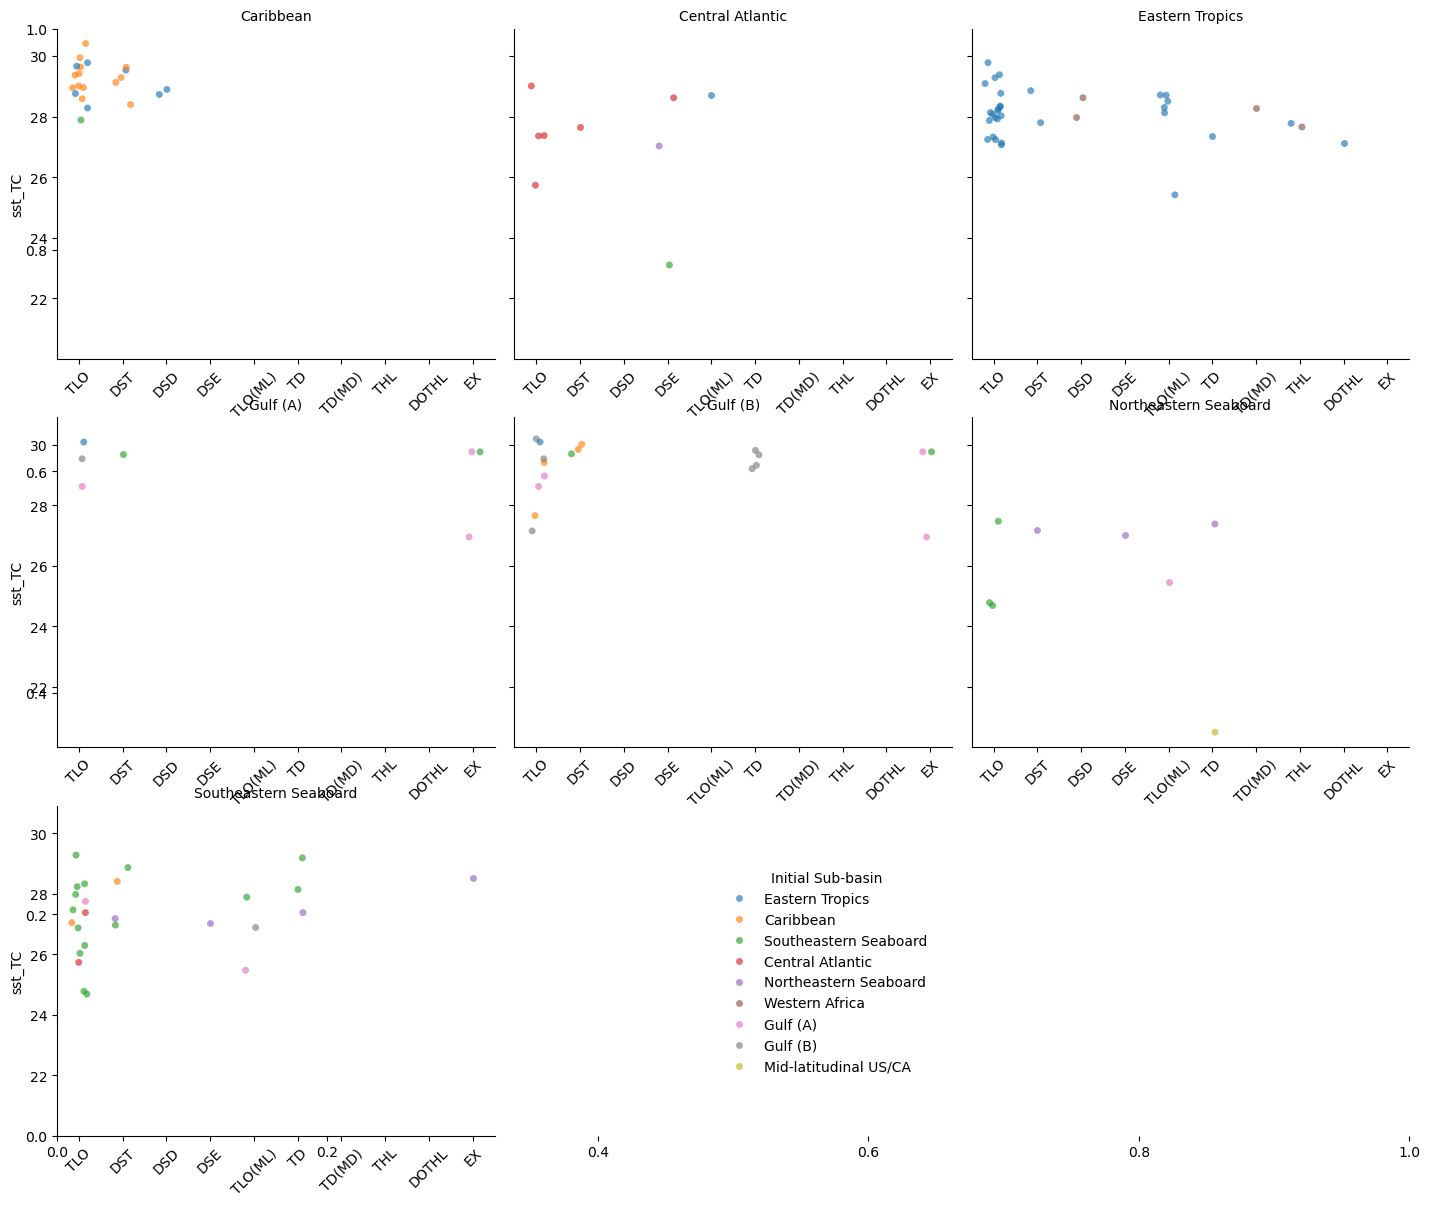

In [ ]:
# now plot
import seaborn as sns

# choose variable
variable = 'sst_TC'

# choose subbasins
piv_plot = piv[~piv['subbasin_TC'].isin(['Mid-latitudinal US/CA', 'Deep Tropics', 'Subtropical Atlantic'])]

# plot
g = sns.catplot(
    data=piv_plot,
    x='Adjusted_Label_ini',
    y=variable,
    hue='subbasin_ini',
    col='subbasin_TC',
    col_wrap=3,
    kind='strip',
    jitter=0.2,
    alpha=0.65,
    height=4,
    aspect=1.2,
    s=25
)

# x-axis labels for all plots
for ax in g.axes.flat:
    ax.tick_params(
        axis='x',
        which='both',
        bottom=True,
        labelbottom=True,
        rotation=45
    )

g.set_axis_labels('', variable)
g.set_titles('{col_name}')

for ax in g.axes.flat:
    ax.tick_params(axis='x', rotation=45)

# move legend to bottom
g._legend.set_bbox_to_anchor((0.5, 0.1))
g._legend.set_title('Initial Sub-basin')
g._legend.set_loc('lower center')

# table for initial classification
ini_table = {
    'HAL': 'High-altitude Low',
    'THL': 'Thermal Low',
    'HATHL': 'High-altitude Thermal Low',
    'DOTHL': 'Deep (Orographic) Thermal Low',
    'TC': 'Tropical Cyclone',
    'TD': 'Tropical Depression',
    'TLO': 'Tropical Low',
    'MD': 'Monsoon Depression',
    'ML': 'Monsoon Low',
    'MS': 'Monsoonal System',
    'TLC': 'Tropical-Like Cylcone',
    'SS (STLC)': 'Subtropical Storm (Subtropical Tropical-Like Cyclone)',
    'PL (PLTC)': 'Polar Low (Polar Tropical-Like Cyclone)',
    'SC': 'Subtropical Cyclone',
    'EX': 'Extratropical Cyclone',
    'DS': 'Disturbance',
    'QS': 'Quasistationary'
}

table_data = [
    [key, value]
    for key, value in ini_table.items()
]

table = plt.table(
    cellText=table_data,
    colLabels=['Code', 'Initial Storm Classification'],
    cellLoc='left',
    colLoc='left',
    bbox=[0.48, 0.02, 0.50, 0.28],
    ax=g.fig.add_subplot(111, frameon=False)
)

table.auto_set_font_size(False)
table.set_fontsize(9)

# style table
for (row, col), cell in table.get_celld().items():
    cell.set_edgecolor('lightgrey')

    if row == 0:
        cell.set_text_props(weight='bold')
        cell.set_facecolor('#D9EAF7')
    else:
        cell.set_facecolor('white')

plt.show()

# plt.tight_layout()
# plt.savefig("images/data_viz/TC_origin/TC/tc_ogSb_vs_initialClassification_1940-2025_sst.png")
# plt.show()
